In [5]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# transforms
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# dataset
class MorphologyDataset(Dataset):
    def __init__(self, image_paths, labels=None, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('L')
        if self.transform:
            img = self.transform(img)
        if self.labels is not None:
            return img, self.labels[idx]
        else:
            return img

# paths
base_dir = r"C:\Users\Liyua\Documents"
control_path = os.path.join(base_dir, "crops_ctl")
fc_path = os.path.join(base_dir, "crops_FC")
lumen_present_path = os.path.join(base_dir, "lumen_present")
lumen_absent_path = os.path.join(base_dir, "lumen_absent")

all_image_paths = [os.path.join(control_path, f) for f in os.listdir(control_path)] + \
                  [os.path.join(fc_path, f) for f in os.listdir(fc_path)]

labeled_image_paths = [os.path.join(lumen_present_path, f) for f in os.listdir(lumen_present_path)] + \
                      [os.path.join(lumen_absent_path, f) for f in os.listdir(lumen_absent_path)]
labeled_labels = [1] * len(os.listdir(lumen_present_path)) + [0] * len(os.listdir(lumen_absent_path))

# loaders
train_imgs, val_imgs, train_labels, val_labels = train_test_split(
    labeled_image_paths, labeled_labels, test_size=0.2, random_state=42
)
train_dataset = MorphologyDataset(train_imgs, train_labels, transform)
val_dataset = MorphologyDataset(val_imgs, val_labels, transform)
all_dataset = MorphologyDataset(all_image_paths, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
all_loader = DataLoader(all_dataset, batch_size=32, shuffle=False)

# models
class Encoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim)
        )
    def forward(self, x):
        return self.encoder(x)

class Decoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.decoder(z)

class Classifier(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )
    def forward(self, z):
        return self.classifier(z)

latent_dim = 32
encoder = Encoder(latent_dim).to(device)
decoder = Decoder(latent_dim).to(device)
classifier = Classifier(latent_dim).to(device)

# training
optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()) + list(classifier.parameters()), lr=1e-3)
recon_loss_fn = nn.MSELoss()
cls_loss_fn = nn.CrossEntropyLoss()

for epoch in range(30):
    encoder.train()
    decoder.train()
    classifier.train()
    total_loss = 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        z = encoder(imgs)
        recon = decoder(z)
        logits = classifier(z)
        loss_recon = recon_loss_fn(recon, imgs)
        loss_cls = cls_loss_fn(logits, labels)
        loss = loss_recon + 0.5 * loss_cls
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: Loss = {total_loss:.4f}")

# extract and save
encoder.eval()
all_latents = []
with torch.no_grad():
    for imgs in tqdm(all_loader):
        imgs = imgs.to(device)
        z = encoder(imgs)
        all_latents.append(z.cpu().numpy())
all_latents = np.concatenate(all_latents, axis=0)
latent_df = pd.DataFrame(all_latents)
latent_df.to_csv("morphology_latent_vectors_32.csv", index=False)
torch.save(encoder.state_dict(), "encoder_32.pth")
torch.save(decoder.state_dict(), "decoder_32.pth")
print("✅ 32-dim encoder and decoder saved.")


Using device: cpu
Epoch 1: Loss = 0.4315
Epoch 2: Loss = 0.4265
Epoch 3: Loss = 0.4197
Epoch 4: Loss = 0.4104
Epoch 5: Loss = 0.3977
Epoch 6: Loss = 0.3817
Epoch 7: Loss = 0.3587
Epoch 8: Loss = 0.3378
Epoch 9: Loss = 0.3161
Epoch 10: Loss = 0.2909
Epoch 11: Loss = 0.2628
Epoch 12: Loss = 0.2355
Epoch 13: Loss = 0.2118
Epoch 14: Loss = 0.1989
Epoch 15: Loss = 0.1792
Epoch 16: Loss = 0.1470
Epoch 17: Loss = 0.1389
Epoch 18: Loss = 0.1229
Epoch 19: Loss = 0.1050
Epoch 20: Loss = 0.0994
Epoch 21: Loss = 0.0878
Epoch 22: Loss = 0.0835
Epoch 23: Loss = 0.0805
Epoch 24: Loss = 0.0766
Epoch 25: Loss = 0.0751
Epoch 26: Loss = 0.0747
Epoch 27: Loss = 0.0743
Epoch 28: Loss = 0.0736
Epoch 29: Loss = 0.0729
Epoch 30: Loss = 0.0725


100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 18.17it/s]

✅ 32-dim encoder and decoder saved.


fused_latents: (89, 32)
morphology_latents: (89, 32)
✅ decoder_32.pth loaded.


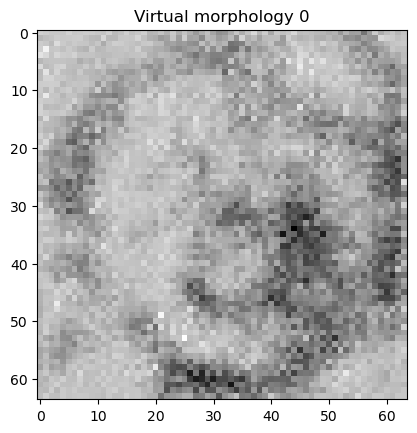

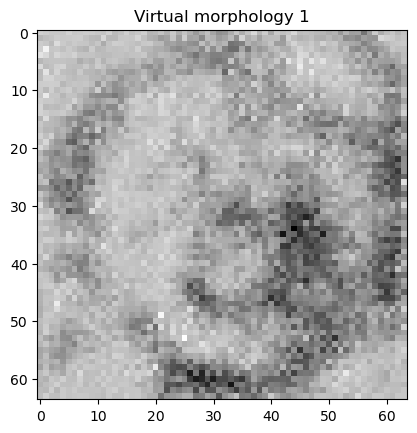

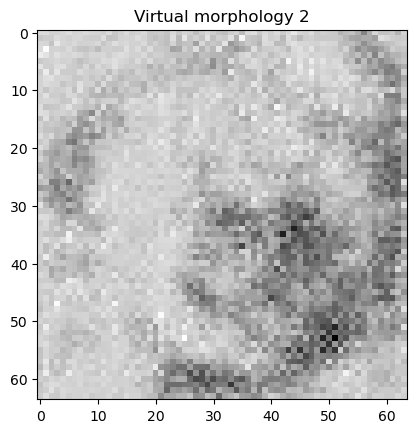

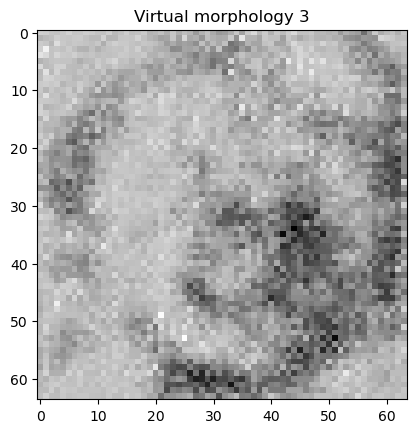

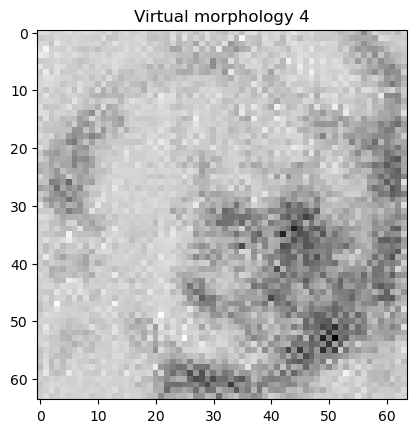

✅ Done. Aligned virtual morphology images saved.


In [8]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ==========================
# Load data
# ==========================
fused_latents = pd.read_csv("fused_shared_latent_vectors.csv").values
morph_latents = pd.read_csv("morphology_latent_vectors_32.csv").values

print("fused_latents:", fused_latents.shape)
print("morphology_latents:", morph_latents.shape)

# sanity check
assert morph_latents.shape[1] == 32

# ==========================
# Align morphology portion
# ==========================
# get fused morphology portion
fused_morph = fused_latents[:, -32:]  # shape (n_samples, 32)

# fit linear regression
ridge = Ridge(alpha=1.0)
ridge.fit(fused_morph, morph_latents)

# transform
aligned_fused_morph = ridge.predict(fused_morph)

# ==========================
# Load trained decoder
# ==========================
class Decoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.decoder(z)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
decoder = Decoder(latent_dim=32).to(device)
decoder.load_state_dict(torch.load("decoder_32.pth"))
decoder.eval()
print("✅ decoder_32.pth loaded.")

# ==========================
# Generate virtual images
# ==========================
virtual_imgs = []
with torch.no_grad():
    for i in range(aligned_fused_morph.shape[0]):
        latent_code = torch.tensor(aligned_fused_morph[i]).float().unsqueeze(0).to(device)
        recon = decoder(latent_code)
        img = recon.cpu().squeeze().numpy()
        virtual_imgs.append(img)

# ==========================
# Visualize
# ==========================
for i in range(min(5, len(virtual_imgs))):
    plt.imshow(virtual_imgs[i], cmap='gray')
    plt.title(f"Virtual morphology {i}")
    plt.show()

# optional save
for i, img in enumerate(virtual_imgs):
    plt.imsave(f"aligned_virtual_morphology_{i}.png", img, cmap='gray')

print("✅ Done. Aligned virtual morphology images saved.")


In [9]:
import pandas as pd
import numpy as np

# load fused latent
fused_latents = pd.read_csv("fused_shared_latent_vectors.csv").values

# define latent dimensions
ipf_like_dims = [4,5,11,13,24,26]
healthy_like_dims = [0,1,2,3,7,8]

# score
ipf_score = fused_latents[:, ipf_like_dims].sum(axis=1)
healthy_score = fused_latents[:, healthy_like_dims].sum(axis=1)

pseudo_labels = (ipf_score > healthy_score).astype(int)

print("Pseudo-label counts:")
print(pd.Series(pseudo_labels).value_counts())


Pseudo-label counts:
0    72
1    17
Name: count, dtype: int64


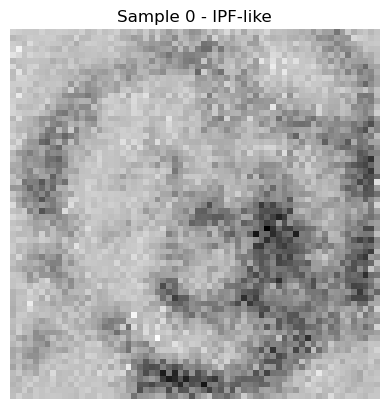

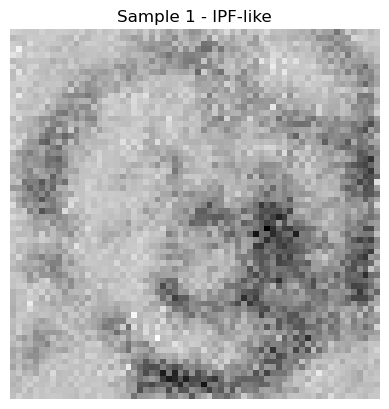

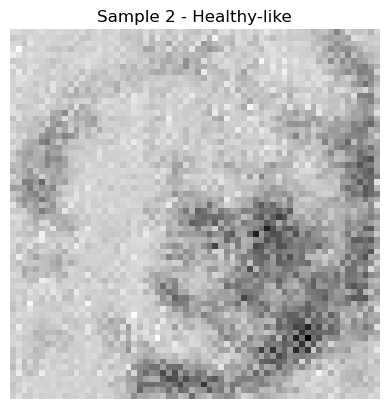

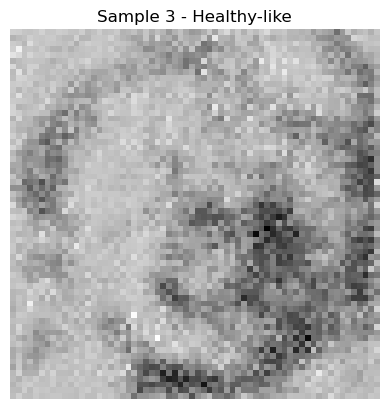

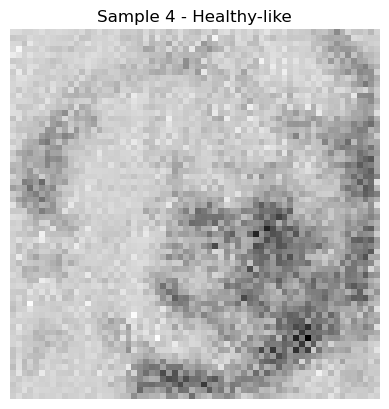

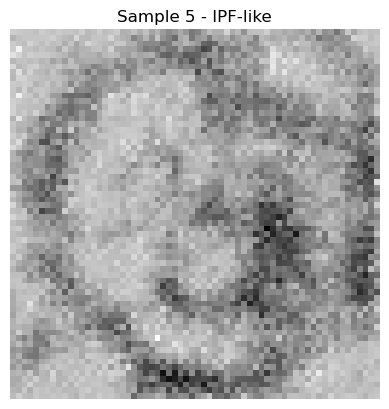

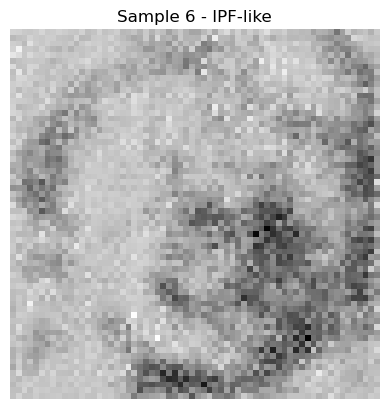

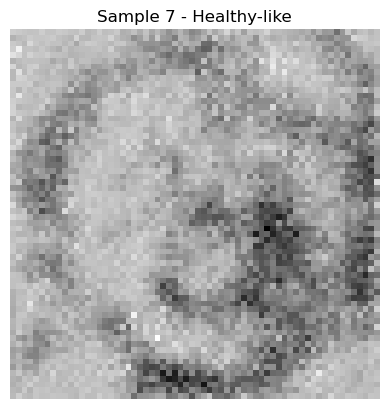

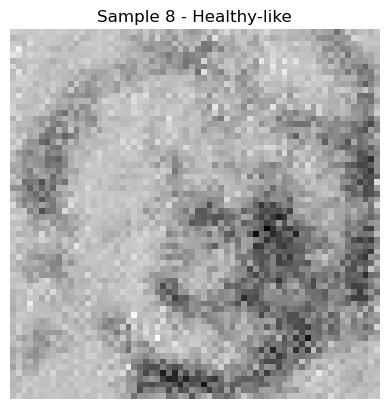

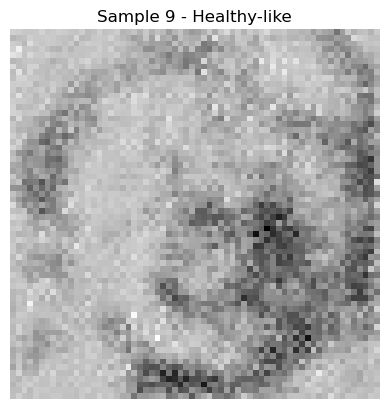

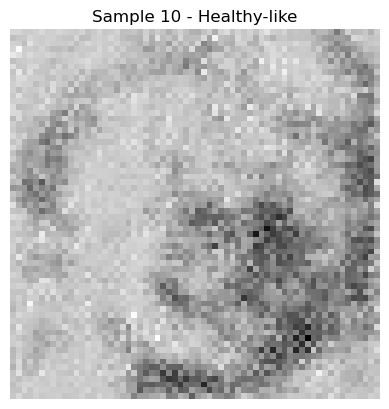

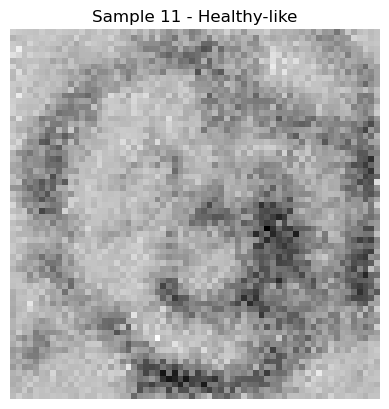

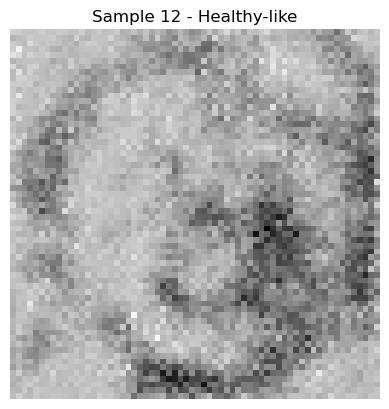

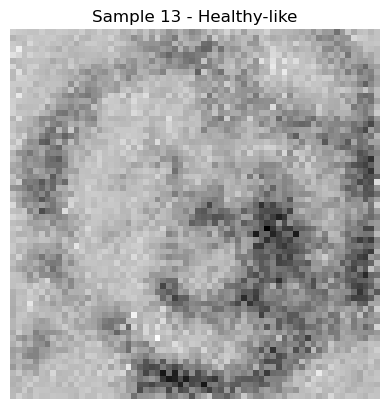

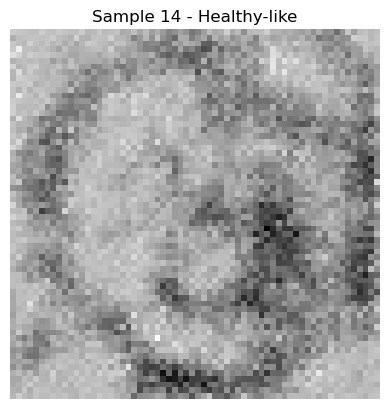

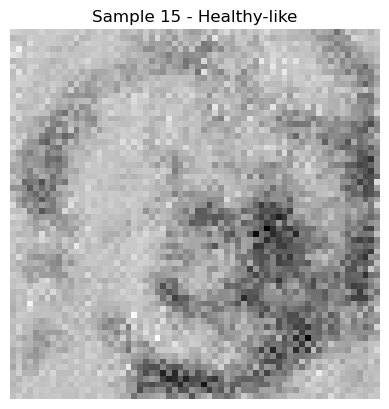

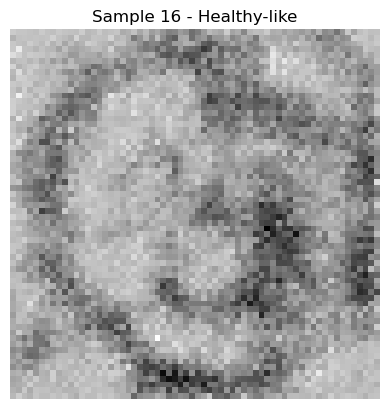

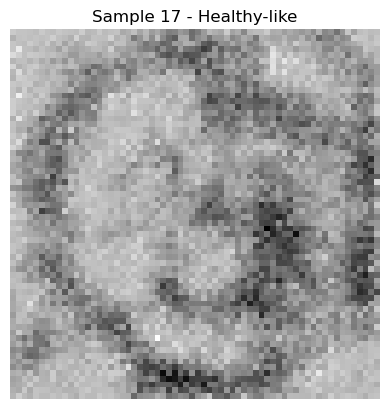

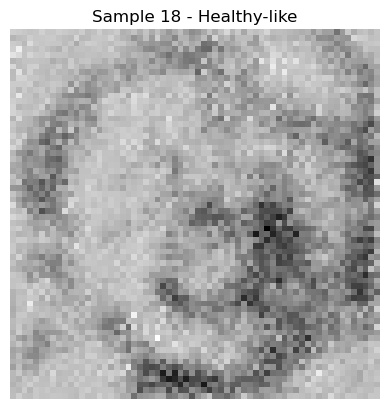

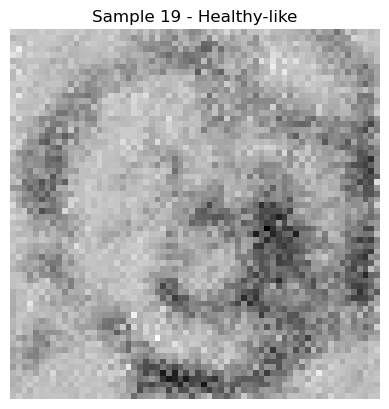

In [10]:
import matplotlib.pyplot as plt

# assuming you still have
# virtual_imgs = [generated images]
# pseudo_labels from the last step

label_names = {0: "Healthy-like", 1: "IPF-like"}

# plot up to 20 samples for sanity
for i in range(min(20, len(virtual_imgs))):
    plt.imshow(virtual_imgs[i], cmap='gray')
    label = pseudo_labels[i]
    plt.title(f"Sample {i} - {label_names[label]}")
    plt.axis("off")
    plt.show()
